# Detección de Fraude en Tarjetas de Crédito — Grupo 33

**Diplomado en Ciencia de Datos y Análisis Avanzado — Proyecto Final Integrador**

**Integrantes:** Mariana Chaile · Eugenia Salcedo Aisa · Sol Kidonakis · Marco Garcia · Esteban Derghazarian

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SolKidonakis/TP_Final_DataScience/blob/main/notebooks/TP_Final_Deteccion_Fraude.ipynb)

Notebook autocontenido (CRISP-DM). Ejecutarlo de arriba hacia abajo regenera **todas** las figuras y tablas de `results/` y el archivo `results/results.json` con las cifras del informe (≈ 10 min en una PC con 4 núcleos; ≈ 40 min en Colab gratuito).

- **Métricas principales:** PR-AUC, Recall y Precision. **Métrica de negocio:** captura Top-100 / Top-500 y cantidad de alertas.
- **Validación:** holdout aleatorio estratificado vs. test temporal por `Time`.
- **Orden de decisiones (fijado antes de mirar los tests):** 1) el modelo se elige con validación cruzada sobre el set de desarrollo; 2) el umbral operativo se elige con predicciones out-of-fold del mismo set; 3) recién entonces se miden los tests.

## 0. Setup y funciones del pipeline

In [1]:
import sys

# En Colab: clonar el repo (para tener README/results) e instalar las versiones fijas.
if "google.colab" in sys.modules:
    import subprocess
    if not __import__("os").path.exists("/content/TP_Final_DataScience"):
        subprocess.run(["git", "clone", "-q", "https://github.com/SolKidonakis/TP_Final_DataScience.git",
                        "/content/TP_Final_DataScience"], check=True)
    # Mismas versiones que requirements.txt: con otras, la CV cambia levemente y puede cambiar el modelo elegido.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numpy==2.1.3", "pandas==2.2.3", "scikit-learn==1.6.1",
                    "xgboost==3.4.1", "lightgbm==4.6.0", "imbalanced-learn==0.14.2", "shap==0.54.1"], check=True)

In [2]:
import gc
import json
import os
import time
import warnings
from pathlib import Path
from urllib.request import urlretrieve

for _k in (
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
):
    os.environ[_k] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False})

ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent, Path("/content/TP_Final_DataScience")] if (p / "README.md").exists()),
    Path.cwd().parent,
)
DATA_CSV = ROOT / "data" / "creditcard.csv"
RESULTS = ROOT / "results"
FIG_DIR = RESULTS / "figures"
TAB_DIR = RESULTS / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

TF_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
PCA_COLS = [f"V{i}" for i in range(1, 29)]
RANDOM_STATE = 42
N_JOBS = min(4, os.cpu_count() or 1)
REVIEW_COST_EUR = 5.0  # supuesto paramétrico: costo de una revisión manual (no hay costos reales del emisor)
DAYS_IN_DATASET = 2
T_START = time.time()
print("ROOT:", ROOT.name, "| N_JOBS:", N_JOBS)

ROOT: TP_Final_DataScience | N_JOBS: 4


In [3]:
# ---- Datos ---------------------------------------------------------------
def load_creditcard(cache_path=None, force_download=False):
    """Carga el dataset ULB (cache local -> mirror de TensorFlow -> OpenML) y valida el esquema."""
    cache_path = Path(cache_path) if cache_path else DATA_CSV
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    if cache_path.exists() and not force_download:
        df = pd.read_csv(cache_path)
    else:
        try:
            urlretrieve(TF_URL, cache_path)
            df = pd.read_csv(cache_path)
        except Exception as exc:
            print("Mirror no disponible, OpenML:", exc)
            from sklearn.datasets import fetch_openml
            df = fetch_openml(data_id=1597, as_frame=True, parser="auto").frame.copy()
            df.to_csv(cache_path, index=False)
    cols = {c.lower(): c for c in df.columns}
    for e in ("time", "amount", "class"):
        if e in cols and cols[e] != e.capitalize():
            df = df.rename(columns={cols[e]: e.capitalize()})
    df["Class"] = pd.to_numeric(df["Class"], errors="coerce").astype(int)
    return df[["Time", *PCA_COLS, "Amount", "Class"]]


def clean_dataframe(df):
    """Elimina duplicados exactos y registra cuántos se quitaron."""
    before, before_fraud = len(df), int(df["Class"].sum())
    out = df.drop_duplicates().reset_index(drop=True)
    out.attrs["n_duplicates_removed"] = before - len(out)
    out.attrs["n_fraud_duplicates_removed"] = before_fraud - int(out["Class"].sum())
    return out


def add_features(df):
    """Amount_log = log1p(Amount); hora del día cíclica (reemplaza a Time crudo, que en el
    test temporal toma valores nunca vistos en entrenamiento)."""
    out = df.copy()
    out["Amount_log"] = np.log1p(out["Amount"].astype(float))
    hour = (out["Time"] % 86400) / 3600.0
    out["Hour"] = hour
    out["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return out


FEATURE_SETS = {
    "completo": [*PCA_COLS, "Amount_log", "Hour_sin", "Hour_cos"],
    "sin_monto": [*PCA_COLS, "Hour_sin", "Hour_cos"],
    "sin_hora": [*PCA_COLS, "Amount_log"],
    "solo_pca": list(PCA_COLS),
    "con_time_crudo": [*PCA_COLS, "Amount_log", "Time"],
}


def feature_target_split(df, feature_set="completo"):
    return df[FEATURE_SETS[feature_set]], df["Class"].astype(int)


def temporal_split_index(df, test_size=0.2):
    """80 % inicial por Time para entrenar, 20 % final para testear."""
    order = np.argsort(df["Time"].to_numpy(), kind="stable")
    cut = int(len(order) * (1 - test_size))
    return order[:cut], order[cut:]

In [4]:
# ---- Métricas ------------------------------------------------------------
def top_k(y_true, score, k):
    """Si revisamos las K operaciones de mayor riesgo, ¿cuántos fraudes encontramos?"""
    y = np.asarray(y_true).astype(int)
    s = np.asarray(score, dtype=float)
    k = min(int(k), len(y))
    idx = np.argsort(-s, kind="stable")[:k]
    found = int(y[idx].sum())
    n_pos = int(y.sum())
    prev = n_pos / len(y)
    prec = found / k
    return {
        "k": k,
        "fraudes": found,
        "precision_k": prec,
        "recall_k": found / n_pos if n_pos else 0.0,
        "lift_k": prec / prev if prev else 0.0,
    }


def top_k_table(y_true, score, amount, ks=(50, 100, 200, 500, 1000)):
    """Tabla Top-K con el monto de fraude capturado."""
    y = np.asarray(y_true).astype(int)
    a = np.asarray(amount, dtype=float)
    order = np.argsort(-np.asarray(score), kind="stable")
    total_amount = a[y == 1].sum()
    rows = []
    for k in ks:
        idx = order[:k]
        t = top_k(y, score, k)
        t["monto_capturado"] = float(a[idx][y[idx] == 1].sum())
        t["pct_monto"] = t["monto_capturado"] / total_amount if total_amount else 0.0
        rows.append(t)
    return pd.DataFrame(rows)


def at_threshold(y_true, score, threshold):
    y = np.asarray(y_true).astype(int)
    pred = np.asarray(score) >= threshold
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    alerts = tp + fp
    return {
        "umbral": float(threshold),
        "alertas": alerts,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": tp / alerts if alerts else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "f1": f1_score(y, pred.astype(int), zero_division=0),
        "fpr": fp / int((y == 0).sum()),
    }


def threshold_for_fpr(y_true, score, fpr):
    """Umbral que deja pasar como alerta una fracción `fpr` de las legítimas."""
    y = np.asarray(y_true).astype(int)
    return float(np.quantile(np.asarray(score)[y == 0], 1 - fpr))


def best_f1_threshold(y_true, score):
    precision, recall, thresholds = precision_recall_curve(y_true, score)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[int(np.argmax(f1[:-1]))])


def summary(y_true, score, ks=(100, 500)):
    row = {
        "pr_auc": average_precision_score(y_true, score),
        "roc_auc": roc_auc_score(y_true, score),
        "prevalencia": float(np.mean(y_true)),
    }
    for k in ks:
        t = top_k(y_true, score, k)
        row[f"fraudes@{k}"] = t["fraudes"]
        row[f"precision@{k}"] = t["precision_k"]
        row[f"recall@{k}"] = t["recall_k"]
        row[f"lift@{k}"] = t["lift_k"]
    return row

In [5]:
# ---- Modelos y pipelines -------------------------------------------------
MODEL_NAMES = ["Logística", "Random Forest", "XGBoost", "LightGBM", "XGBoost + SMOTE"]
COLORS = {
    "Logística": "#4C78A8",
    "Random Forest": "#54A24B",
    "XGBoost": "#E45756",
    "LightGBM": "#F58518",
    "XGBoost + SMOTE": "#B279A2",
    "Regla: monto alto": "#9D755D",
    "Ranking aleatorio": "#999999",
}


def scale_pos_weight(y):
    y = np.asarray(y).astype(int)
    return float((y == 0).sum() / max((y == 1).sum(), 1))


def make_estimator(name, y_train, random_state=RANDOM_STATE):
    spw = scale_pos_weight(y_train)
    if name == "Logística":
        return LogisticRegression(class_weight="balanced", max_iter=2000, random_state=random_state)
    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=200, max_depth=12, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=random_state,
        )
    if name in ("XGBoost", "XGBoost + SMOTE"):
        return XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, scale_pos_weight=1.0 if name == "XGBoost + SMOTE" else spw,
            eval_metric="aucpr", tree_method="hist", n_jobs=N_JOBS, random_state=random_state,
        )
    if name == "LightGBM":
        # is_unbalance=True resultó inestable (PR-AUC ~ 0): se usa un peso moderado (raíz de neg/pos) y regularización.
        return LGBMClassifier(
            n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=50,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
            scale_pos_weight=float(np.sqrt(spw)), n_jobs=N_JOBS, random_state=random_state, verbose=-1,
        )
    raise ValueError(name)


def build_pipeline(name, feature_names, y_train, random_state=RANDOM_STATE):
    """Escalado (y SMOTE, si corresponde) dentro del Pipeline: nada ve datos de validación/test."""
    scale_cols = [c for c in ("Amount_log", "Time") if c in feature_names]
    pre = ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough",
                            verbose_feature_names_out=False)
    clf = make_estimator(name, y_train, random_state)
    if name == "XGBoost + SMOTE":
        return ImbPipeline([("pre", pre), ("smote", SMOTE(sampling_strategy=0.1, random_state=random_state)), ("clf", clf)])
    return Pipeline([("pre", pre), ("clf", clf)])


def predict_score(pipe, X):
    return pipe.predict_proba(X)[:, 1]


def save_table(df, name):
    df.to_csv(TAB_DIR / name, index=False)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Datos, limpieza y EDA  *(CRISP-DM: comprensión y preparación de datos)*

In [6]:
df_raw = load_creditcard()
print(df_raw.shape, "fraudes originales:", int(df_raw["Class"].sum()), f"({df_raw['Class'].mean():.4%})")
print("Nulos:", int(df_raw.isna().sum().sum()))
clean = clean_dataframe(df_raw)
df = add_features(clean)
print("Duplicados eliminados:", clean.attrs["n_duplicates_removed"], "(de los cuales fraudes:", clean.attrs["n_fraud_duplicates_removed"], ")")
print(df.shape, "fraudes:", int(df["Class"].sum()), f"({df['Class'].mean():.4%})")

quality = {
    "n_raw": int(len(df_raw)),
    "fraud_raw": int(df_raw["Class"].sum()),
    "duplicados": int(clean.attrs["n_duplicates_removed"]),
    "duplicados_fraude": int(clean.attrs["n_fraud_duplicates_removed"]),
    "n": int(len(df)),
    "fraud": int(df["Class"].sum()),
    "prevalencia": float(df["Class"].mean()),
    "nulos": int(df_raw.isna().sum().sum()),
    "monto_cero": int((df["Amount"] == 0).sum()),
    "monto_cero_fraude": int(((df["Amount"] == 0) & (df["Class"] == 1)).sum()),
    "monto_mediana_legit": float(df.loc[df.Class == 0, "Amount"].median()),
    "monto_mediana_fraude": float(df.loc[df.Class == 1, "Amount"].median()),
    "monto_media_fraude": float(df.loc[df.Class == 1, "Amount"].mean()),
    "monto_max": float(df["Amount"].max()),
    "monto_max_fraude": float(df.loc[df.Class == 1, "Amount"].max()),
    "monto_p99": float(df["Amount"].quantile(0.99)),
    "monto_total_fraude": float(df.loc[df.Class == 1, "Amount"].sum()),
    "horas": float(df["Time"].max() / 3600),
}
df.head()

(284807, 31) fraudes originales: 492 (0.1727%)
Nulos: 0


Duplicados eliminados: 1081 (de los cuales fraudes: 19 )
(283726, 35) fraudes: 473 (0.1667%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Class,Amount_log,Hour,Hour_sin,Hour_cos
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0,5.014760,0.000000,0.000000,1.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.167170,0.125895,-0.008983,0.014724,2.69,0,1.305626,0.000000,0.000000,1.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,5.939276,0.000278,0.000073,1.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.647376,-0.221929,0.062723,0.061458,123.50,0,4.824306,0.000278,0.000073,1.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.206010,0.502292,0.219422,0.215153,69.99,0,4.262539,0.000556,0.000145,1.0


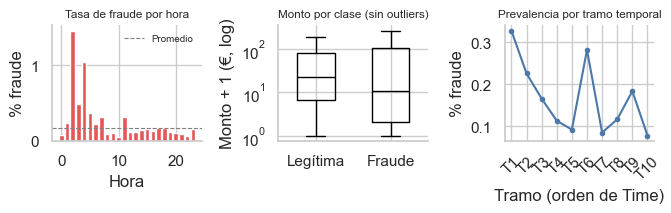

Correlación absoluta con Class (top 6): {'V17': -0.313, 'V14': -0.293, 'V12': -0.251, 'V10': -0.207, 'V16': -0.187, 'V3': -0.182}


In [7]:
# Fraude por hora del día y por tramo temporal (diez tramos de igual cantidad de operaciones)
hour = df["Hour"].astype(int)
by_hour = df.groupby(hour).agg(transacciones=("Class", "size"), fraudes=("Class", "sum")).reset_index()
by_hour["tasa"] = by_hour["fraudes"] / by_hour["transacciones"]
save_table(by_hour.rename(columns={"Hour": "hora"}), "eda_por_hora.csv")

ordered = df.sort_values("Time").reset_index(drop=True)
ordered["tramo"] = pd.qcut(np.arange(len(ordered)), 10, labels=[f"T{i}" for i in range(1, 11)])
by_tramo = ordered.groupby("tramo", observed=True).agg(transacciones=("Class", "size"), fraudes=("Class", "sum")).reset_index()
by_tramo["tasa"] = by_tramo["fraudes"] / by_tramo["transacciones"]
save_table(by_tramo, "eda_por_tramo_temporal.csv")

corr = df[PCA_COLS + ["Amount", "Class"]].corr()["Class"].drop("Class")
top_corr = corr.abs().sort_values(ascending=False).head(6)
night = df["Hour"] < 6
eda = {
    "tasa_noche": float(df.loc[night, "Class"].mean()),
    "tasa_dia": float(df.loc[~night, "Class"].mean()),
    "pct_tx_noche": float(night.mean()),
    "hora_max_tasa": int(by_hour.loc[by_hour["tasa"].idxmax(), "Hour"]),
    "tasa_max_hora": float(by_hour["tasa"].max()),
    "tramo_tasa_min": float(by_tramo["tasa"].min()),
    "tramo_tasa_max": float(by_tramo["tasa"].max()),
    "top_corr": {k: float(corr[k]) for k in top_corr.index},
}

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.3))
ax = axes[0]
ax.bar(by_hour["Hour"], by_hour["tasa"] * 100, color="#E45756")
ax.axhline(df["Class"].mean() * 100, color="gray", ls="--", lw=0.8, label="Promedio")
ax.set_title("Tasa de fraude por hora", fontsize=8.5); ax.set_xlabel("Hora"); ax.set_ylabel("% fraude"); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
ax.boxplot([df.loc[df.Class == 0, "Amount"] + 1, df.loc[df.Class == 1, "Amount"] + 1],
           showfliers=False, widths=0.5, medianprops={"color": "black"})
ax.set_xticks([1, 2], ["Legítima", "Fraude"])
ax.set_yscale("log"); ax.set_title("Monto por clase (sin outliers)", fontsize=8.5); ax.set_ylabel("Monto + 1 (€, log)")
ax = axes[2]
ax.plot(by_tramo["tramo"].astype(str), by_tramo["tasa"] * 100, marker="o", ms=3, color="#4C78A8")
ax.set_title("Prevalencia por tramo temporal", fontsize=8.5); ax.set_xlabel("Tramo (orden de Time)"); ax.set_ylabel("% fraude")
ax.tick_params(axis="x", rotation=45)
save_fig(fig, "fig1_eda.png")
print("Correlación absoluta con Class (top 6):", {k: round(v, 3) for k, v in eda["top_corr"].items()})

## 2. Splits: aleatorio estratificado vs. temporal

- **Desarrollo / test estable:** 80/20 estratificado, separado antes de cualquier ajuste. El 80 % de desarrollo se usa para validación cruzada, elección del modelo y del umbral; el 20 % solo para evaluar.
- **Train / test temporal:** primer 80 % de las operaciones por `Time` para entrenar y último 20 % para testear (¿generaliza hacia el futuro?).

In [8]:
X, y = feature_target_split(df)
idx = np.arange(len(df))
idx_dev, idx_test = train_test_split(idx, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
idx_tr_t, idx_te_t = temporal_split_index(df, 0.2)

X_dev, y_dev, X_te, y_te = X.iloc[idx_dev], y.iloc[idx_dev], X.iloc[idx_test], y.iloc[idx_test]
X_tr_t, y_tr_t, X_te_t, y_te_t = X.iloc[idx_tr_t], y.iloc[idx_tr_t], X.iloc[idx_te_t], y.iloc[idx_te_t]
amount_te = df["Amount"].iloc[idx_test]
amount_te_t = df["Amount"].iloc[idx_te_t]

print("Aleatorio — desarrollo/test fraudes:", int(y_dev.sum()), int(y_te.sum()), "| n_test:", len(y_te))
print("Temporal  — train/test fraudes:", int(y_tr_t.sum()), int(y_te_t.sum()), "| n_test:", len(y_te_t))

Aleatorio — desarrollo/test fraudes: 378 95 | n_test: 56746
Temporal  — train/test fraudes: 399 74 | n_test: 56746


## 3. Selección del modelo y del umbral (solo con el set de desarrollo)

Validación cruzada estratificada de 5 folds. **Regla de selección (fijada antes de mirar los tests):**
1. Gana la mayor PR-AUC media en CV.
2. Los modelos a menos de un desvío estándar de la mejor quedan empatados.
3. Entre los empatados se elige la mayor Precision@100 media de CV y, si persiste el empate, la mayor PR-AUC media de CV.

El **umbral operativo** es el que maximiza el F1 sobre las predicciones *out-of-fold* (cada transacción predicha por un modelo que no la vio entrenar).

In [9]:
def cross_validate(X_dev, y_dev, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows, oof = [], {}
    for name in MODEL_NAMES:
        t0 = time.time()
        scores = np.zeros(len(y_dev))
        fold_rows = []
        for tr, va in skf.split(X_dev, y_dev):
            pipe = build_pipeline(name, list(X_dev.columns), y_dev.iloc[tr])
            pipe.fit(X_dev.iloc[tr], y_dev.iloc[tr])
            s = predict_score(pipe, X_dev.iloc[va])
            scores[va] = s
            fold_rows.append(summary(y_dev.iloc[va], s, ks=(100,)))
        f = pd.DataFrame(fold_rows)
        rows.append({
            "modelo": name,
            "pr_auc_media": f["pr_auc"].mean(),
            "pr_auc_desvio": f["pr_auc"].std(ddof=1),
            "roc_auc_media": f["roc_auc"].mean(),
            "precision@100_media": f["precision@100"].mean(),
            "segundos": time.time() - t0,
        })
        oof[name] = scores
        print(f"  CV {name:16s} PR-AUC {f['pr_auc'].mean():.3f} ± {f['pr_auc'].std(ddof=1):.3f}", flush=True)
    return pd.DataFrame(rows), oof


def select_model(cv):
    best = cv.loc[cv["pr_auc_media"].idxmax()]
    cut = best["pr_auc_media"] - best["pr_auc_desvio"]
    tied = cv[cv["pr_auc_media"] >= cut]
    if "Logística" in tied["modelo"].values:  # empate con el baseline interpretable -> baseline
        chosen = "Logística"
    else:
        ranked = tied.assign(p100=tied["precision@100_media"].round(3)).sort_values(["p100", "pr_auc_media"], ascending=False)
        chosen = ranked.iloc[0]["modelo"]
    return {"elegido": chosen, "empatados": tied["modelo"].tolist(), "corte_empate": float(cut)}


cv, oof = cross_validate(X_dev, y_dev)
save_table(cv, "cv_seleccion.csv")
seleccion = select_model(cv)
chosen = seleccion["elegido"]
threshold = best_f1_threshold(y_dev, oof[chosen])
oof_at_thr = at_threshold(y_dev, oof[chosen], threshold)
print(f"\nModelo elegido: {chosen} | empatados en CV: {seleccion['empatados']}")
print(f"Umbral operativo (máx. F1 out-of-fold): {threshold:.3f} -> {oof_at_thr['alertas']} alertas en desarrollo, "
      f"Precision {oof_at_thr['precision']:.3f}, Recall {oof_at_thr['recall']:.3f}")
cv

  CV Logística        PR-AUC 0.740 ± 0.025


  CV Random Forest    PR-AUC 0.828 ± 0.040


  CV XGBoost          PR-AUC 0.850 ± 0.036


  CV LightGBM         PR-AUC 0.830 ± 0.034


  CV XGBoost + SMOTE  PR-AUC 0.845 ± 0.034



Modelo elegido: Random Forest | empatados en CV: ['Random Forest', 'XGBoost', 'LightGBM', 'XGBoost + SMOTE']
Umbral operativo (máx. F1 out-of-fold): 0.574 -> 338 alertas en desarrollo, Precision 0.891, Recall 0.796


,modelo,pr_auc_media,pr_auc_desvio,roc_auc_media,precision@100_media,segundos
0,Logística,0.739897,0.025135,0.979342,0.626,1.781805
1,Random Forest,0.827943,0.040270,0.982408,0.644,165.200811
2,XGBoost,0.849572,0.035820,0.982715,0.642,25.857537
3,LightGBM,0.829528,0.034434,0.977371,0.632,10.451282
4,XGBoost + SMOTE,0.844819,0.034040,0.978737,0.638,27.751673


## 4. Test estable (holdout aleatorio): comparación de modelos y Top-K

In [10]:
def evaluate_split(X_tr, y_tr, X_te, y_te, amount_te, label):
    """Entrena cada modelo y guarda solo los scores. Incluye dos baselines: azar y regla 'monto alto'."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = {"Ranking aleatorio": rng.random(len(y_te)), "Regla: monto alto": amount_te.to_numpy()}
    pipes = {}
    for name in MODEL_NAMES:
        t0 = time.time()
        pipe = build_pipeline(name, list(X_tr.columns), y_tr)
        pipe.fit(X_tr, y_tr)
        scores[name] = predict_score(pipe, X_te)
        pipes[name] = pipe
        print(f"  {label} {name:16s} PR-AUC {average_precision_score(y_te, scores[name]):.3f} ({time.time() - t0:.0f}s)", flush=True)
    table = pd.DataFrame([{"modelo": n, **summary(y_te, s)} for n, s in scores.items()])
    save_table(table, f"test_{label}.csv")
    return table, scores, pipes


test_st, scores_st, pipes_st = evaluate_split(X_dev, y_dev, X_te, y_te, amount_te, "estable")
op_st = at_threshold(y_te, scores_st[chosen], threshold)
topk_st = top_k_table(y_te, scores_st[chosen], amount_te)
save_table(topk_st, "topk_estable.csv")
display(test_st.round(3))
display(topk_st.round(3))

  estable Logística        PR-AUC 0.681 (0s)


  estable Random Forest    PR-AUC 0.803 (45s)


  estable XGBoost          PR-AUC 0.813 (6s)


  estable LightGBM         PR-AUC 0.801 (2s)


  estable XGBoost + SMOTE  PR-AUC 0.806 (7s)


,modelo,pr_auc,roc_auc,prevalencia,fraudes@100,precision@100,recall@100,lift@100,fraudes@500,precision@500,recall@500,lift@500
0,Ranking aleatorio,0.002,0.477,0.002,0,0.00,0.000,0.000,1,0.002,0.011,1.195
1,Regla: monto alto,0.003,0.451,0.002,0,0.00,0.000,0.000,2,0.004,0.021,2.389
2,Logística,0.681,0.964,0.002,74,0.74,0.779,442.021,80,0.160,0.842,95.572
3,Random Forest,0.803,0.971,0.002,77,0.77,0.811,459.941,80,0.160,0.842,95.572
4,XGBoost,0.813,0.972,0.002,77,0.77,0.811,459.941,82,0.164,0.863,97.962
5,LightGBM,0.801,0.968,0.002,75,0.75,0.789,447.995,79,0.158,0.832,94.378
6,XGBoost + SMOTE,0.806,0.980,0.002,75,0.75,0.789,447.995,81,0.162,0.853,96.767


,k,fraudes,precision_k,recall_k,lift_k,monto_capturado,pct_monto
0,50,49,0.980,0.516,585.380,3456.75,0.234
1,100,77,0.770,0.811,459.941,10980.73,0.744
2,200,79,0.395,0.832,235.944,11707.73,0.793
3,500,80,0.160,0.842,95.572,11708.49,0.793
4,1000,82,0.082,0.863,48.981,12167.76,0.824


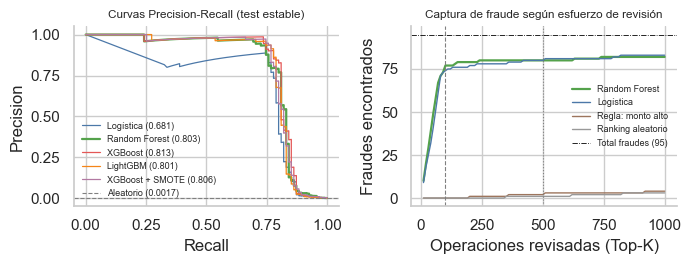

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8))
ax = axes[0]
for name in MODEL_NAMES:
    p, r, _ = precision_recall_curve(y_te, scores_st[name])
    ax.plot(r, p, lw=1.6 if name == chosen else 0.9, color=COLORS[name], label=f"{name} ({average_precision_score(y_te, scores_st[name]):.3f})")
ax.axhline(np.mean(y_te), color="gray", ls="--", lw=0.8, label=f"Aleatorio ({np.mean(y_te):.4f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Curvas Precision-Recall (test estable)", fontsize=8.5)
ax.legend(frameon=False, loc="lower left", fontsize=6.5)
ax = axes[1]
ks = np.arange(10, 1001, 10)
yv = np.asarray(y_te)
for name in [chosen, "Logística", "Regla: monto alto", "Ranking aleatorio"]:
    order = np.argsort(-np.asarray(scores_st[name]), kind="stable")
    ax.plot(ks, np.cumsum(yv[order])[ks - 1], color=COLORS[name], lw=1.6 if name == chosen else 1.0, label=name)
ax.axvline(100, color="gray", ls="--", lw=0.8); ax.axvline(500, color="gray", ls=":", lw=0.8)
ax.axhline(yv.sum(), color="black", lw=0.6, ls="-.", label=f"Total fraudes ({int(yv.sum())})")
ax.set_xlabel("Operaciones revisadas (Top-K)"); ax.set_ylabel("Fraudes encontrados")
ax.set_title("Captura de fraude según esfuerzo de revisión", fontsize=8.5)
ax.legend(frameon=False, loc="center right", fontsize=6.5)
save_fig(fig, "fig2_test_estable.png")

## 5. Validación temporal

  temporal Logística        PR-AUC 0.757 (0s)


  temporal Random Forest    PR-AUC 0.815 (47s)


  temporal XGBoost          PR-AUC 0.791 (6s)


  temporal LightGBM         PR-AUC 0.762 (3s)


  temporal XGBoost + SMOTE  PR-AUC 0.789 (7s)


,modelo,pr_auc,roc_auc,prevalencia,fraudes@100,precision@100,recall@100,lift@100,fraudes@500,precision@500,recall@500,lift@500
0,Ranking aleatorio,0.001,0.485,0.001,0,0.00,0.000,0.000,0,0.000,0.000,0.000
1,Regla: monto alto,0.001,0.385,0.001,0,0.00,0.000,0.000,2,0.004,0.027,3.067
2,Logística,0.757,0.985,0.001,59,0.59,0.797,452.434,64,0.128,0.865,98.155
3,Random Forest,0.815,0.989,0.001,60,0.60,0.811,460.103,65,0.130,0.878,99.689
4,XGBoost,0.791,0.982,0.001,58,0.58,0.784,444.766,63,0.126,0.851,96.622
5,LightGBM,0.762,0.981,0.001,58,0.58,0.784,444.766,63,0.126,0.851,96.622
6,XGBoost + SMOTE,0.789,0.987,0.001,58,0.58,0.784,444.766,61,0.122,0.824,93.554


,k,fraudes,precision_k,recall_k,lift_k,monto_capturado,pct_monto
0,50,49,0.980,0.662,751.501,3533.32,0.457
1,100,60,0.600,0.811,460.103,5336.94,0.691
2,200,62,0.310,0.838,237.720,5357.47,0.693
3,500,65,0.130,0.878,99.689,6357.72,0.823
4,1000,66,0.066,0.892,50.611,6370.03,0.824


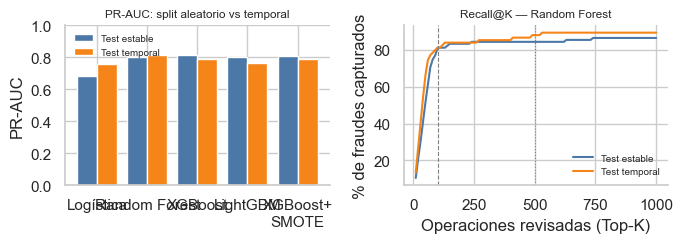

In [12]:
test_tm, scores_tm, _ = evaluate_split(X_tr_t, y_tr_t, X_te_t, y_te_t, amount_te_t, "temporal")
op_tm = at_threshold(y_te_t, scores_tm[chosen], threshold)
topk_tm = top_k_table(y_te_t, scores_tm[chosen], amount_te_t)
save_table(topk_tm, "topk_temporal.csv")
temporal_meta = {
    "corte_horas": float(df["Time"].iloc[idx_te_t].min() / 3600),
    "n_train": int(len(idx_tr_t)), "n_test": int(len(idx_te_t)),
    "fraude_train": int(y_tr_t.sum()), "fraude_test": int(y_te_t.sum()),
    "prev_train": float(y_tr_t.mean()), "prev_test": float(y_te_t.mean()),
}
display(test_tm.round(3))
display(topk_tm.round(3))

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
ax = axes[0]
x = np.arange(len(MODEL_NAMES))
ax.bar(x - 0.2, test_st.set_index("modelo").loc[MODEL_NAMES, "pr_auc"], 0.4, label="Test estable", color="#4C78A8")
ax.bar(x + 0.2, test_tm.set_index("modelo").loc[MODEL_NAMES, "pr_auc"], 0.4, label="Test temporal", color="#F58518")
ax.set_xticks(x, [n.replace(" + ", "+\n") for n in MODEL_NAMES]); ax.set_ylabel("PR-AUC"); ax.set_ylim(0, 1)
ax.set_title("PR-AUC: split aleatorio vs temporal", fontsize=8.5); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
for label, yy, ss, c in [("Test estable", y_te, scores_st[chosen], "#4C78A8"), ("Test temporal", y_te_t, scores_tm[chosen], "#F58518")]:
    yy = np.asarray(yy)
    order = np.argsort(-np.asarray(ss), kind="stable")
    ax.plot(ks, np.cumsum(yy[order])[ks - 1] / yy.sum() * 100, color=c, label=label)
ax.axvline(100, color="gray", ls="--", lw=0.8); ax.axvline(500, color="gray", ls=":", lw=0.8)
ax.set_xlabel("Operaciones revisadas (Top-K)"); ax.set_ylabel("% de fraudes capturados")
ax.set_title(f"Recall@K — {chosen}", fontsize=8.5); ax.legend(frameon=False, loc="lower right", fontsize=7)
save_fig(fig, "fig3_temporal.png")

## 6. Umbral operativo, carga de alertas y auditoría por segmentos

El umbral sale de las predicciones out-of-fold (sección 3), **no** del test. Se contrasta con la regla "FPR = 5 %" de la pre-entrega, que sobre las ~56.650 legítimas del test implicaría ~2.800 alertas falsas.

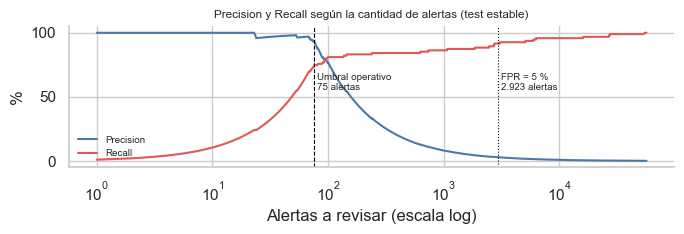

Umbral operativo — test estable : {'umbral': 0.574, 'alertas': 75, 'tp': 70, 'fp': 5, 'fn': 25, 'precision': 0.933, 'recall': 0.737, 'f1': 0.824, 'fpr': 0.0}
Umbral operativo — test temporal: {'umbral': 0.574, 'alertas': 53, 'tp': 52, 'fp': 1, 'fn': 22, 'precision': 0.981, 'recall': 0.703, 'f1': 0.819, 'fpr': 0.0}
Umbral con FPR = 5 % — test estable: {'umbral': 0.018, 'alertas': 2923, 'tp': 87, 'fp': 2836, 'fn': 8, 'precision': 0.03, 'recall': 0.916, 'f1': 0.058, 'fpr': 0.05}


In [13]:
fpr_thr = threshold_for_fpr(y_te, scores_st[chosen], 0.05)
fpr5 = at_threshold(y_te, scores_st[chosen], fpr_thr)

p, r, t = precision_recall_curve(y_te, scores_st[chosen])
alerts = np.array([(scores_st[chosen] >= th).sum() for th in t])
fig, ax = plt.subplots(figsize=(7.0, 2.5))
ax.plot(alerts, p[:-1] * 100, color="#4C78A8", label="Precision")
ax.plot(alerts, r[:-1] * 100, color="#E45756", label="Recall")
for th, lab, ls in [(threshold, "Umbral operativo", "--"), (fpr_thr, "FPR = 5 %", ":")]:
    n = int((np.asarray(scores_st[chosen]) >= th).sum())
    ax.axvline(n, color="black", ls=ls, lw=0.8)
    ax.text(n * 1.08, 55, f"{lab}\n{n:,} alertas".replace(",", "."), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("Alertas a revisar (escala log)"); ax.set_ylabel("%")
ax.set_title("Precision y Recall según la cantidad de alertas (test estable)", fontsize=8.5)
ax.legend(frameon=False, loc="lower left", fontsize=7)
save_fig(fig, "fig5_umbral_alertas.png")

print("Umbral operativo — test estable :", {k: round(v, 3) for k, v in op_st.items()})
print("Umbral operativo — test temporal:", {k: round(v, 3) for k, v in op_tm.items()})
print("Umbral con FPR = 5 % — test estable:", {k: round(v, 3) for k, v in fpr5.items()})

In [14]:
def segment_audit(df_te, score, threshold):
    d = df_te[["Amount", "Hour", "Class"]].copy()
    d["alerta"] = np.asarray(score) >= threshold
    d["tramo_monto"] = pd.cut(d["Amount"], [-0.01, 1, 10, 100, np.inf], labels=["≤ €1", "€1–10", "€10–100", "> €100"])
    d["franja"] = pd.cut(d["Hour"], [-0.01, 6, 18, 24], labels=["Noche (0–6 h)", "Día (6–18 h)", "Tarde/noche (18–24 h)"])
    rows = []
    for col, title in [("tramo_monto", "Monto"), ("franja", "Franja horaria")]:
        for g, sub in d.groupby(col, observed=True):
            fr = int(sub["Class"].sum()); al = int(sub["alerta"].sum()); tp = int((sub["alerta"] & (sub["Class"] == 1)).sum())
            rows.append({"atributo": title, "grupo": str(g), "transacciones": len(sub), "fraudes": fr, "tasa": fr / len(sub),
                         "alertas": al, "recall": tp / fr if fr else np.nan, "precision": tp / al if al else np.nan})
    return pd.DataFrame(rows)


audit = segment_audit(df.iloc[idx_test], scores_st[chosen], threshold)
save_table(audit, "auditoria_segmentos.csv")
audit.round(3)

,atributo,grupo,transacciones,fraudes,tasa,alertas,recall,precision
0,Monto,≤ €1,6202,35,0.006,27,0.743,0.963
1,Monto,€1–10,13974,12,0.001,7,0.500,0.857
2,Monto,€10–100,25367,22,0.001,23,0.955,0.913
3,Monto,> €100,11203,26,0.002,18,0.654,0.944
4,Franja horaria,Noche (0–6 h),4892,27,0.006,23,0.815,0.957
5,Franja horaria,Día (6–18 h),33348,49,0.001,37,0.714,0.946
6,Franja horaria,Tarde/noche (18–24 h),18506,19,0.001,15,0.684,0.867


## 7. Escenario económico

Supuesto paramétrico y explícito: **cada revisión manual cuesta €5**. El beneficio es el monto de los fraudes detectados; el neto resta el costo de revisión. Se compara contra una regla estática (revisar las 500 operaciones de mayor monto) y contra el criterio FPR = 5 %. Los valores "por día" extrapolan el test a los 2 días del dataset.

In [15]:
def economic_scenario(y_te, score, rule_score, amount_te, threshold, n_total, n_test):
    y = np.asarray(y_te).astype(int)
    a = np.asarray(amount_te, dtype=float)
    per_day = (n_total / DAYS_IN_DATASET) / n_test

    def row(name, selected):
        alerts = int(selected.sum()); tp = int((selected & (y == 1)).sum())
        detected = float(a[selected & (y == 1)].sum()); cost = alerts * REVIEW_COST_EUR
        return {"escenario": name, "alertas": alerts, "fraudes": tp, "recall": tp / y.sum(),
                "precision": tp / alerts if alerts else 0.0, "monto_detectado": detected, "costo_revision": cost,
                "neto": detected - cost, "alertas_dia": alerts * per_day, "neto_dia": (detected - cost) * per_day}

    def top_mask(s, k):
        m = np.zeros(len(s), dtype=bool)
        m[np.argsort(-np.asarray(s), kind="stable")[:k]] = True
        return m

    rows = [
        row("Regla estática: Top-500 por monto", top_mask(rule_score, 500)),
        row("Modelo: Top-100", top_mask(score, 100)),
        row("Modelo: Top-500", top_mask(score, 500)),
        row("Modelo: umbral operativo", np.asarray(score) >= threshold),
        row("Modelo: umbral con FPR = 5 %", np.asarray(score) >= fpr_thr),
    ]
    return pd.DataFrame(rows), {"factor_dia": per_day, "umbral_fpr5": fpr_thr, "monto_fraude_test": float(a[y == 1].sum())}


econ, econ_meta = economic_scenario(y_te, scores_st[chosen], scores_st["Regla: monto alto"], amount_te,
                                    threshold, len(df), len(idx_test))
save_table(econ, "escenario_economico.csv")
econ.round(3)

,escenario,alertas,fraudes,recall,precision,monto_detectado,costo_revision,neto,alertas_dia,neto_dia
0,Regla estática: Top-500 por monto,500,2,0.021,0.004,3163.93,2500.0,663.93,1249.982,1659.802
1,Modelo: Top-100,100,77,0.811,0.770,10980.73,500.0,10480.73,249.996,26201.456
2,Modelo: Top-500,500,80,0.842,0.160,11708.49,2500.0,9208.49,1249.982,23020.900
3,Modelo: umbral operativo,75,70,0.737,0.933,8905.10,375.0,8530.10,187.497,21324.949
4,Modelo: umbral con FPR = 5 %,2923,87,0.916,0.030,13892.56,14615.0,-722.44,7307.397,-1806.075


## 8. Interpretación (SHAP)

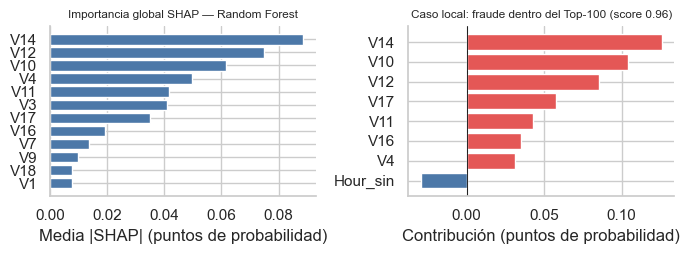

In [16]:
def shap_values(pipe, Xs):
    import shap
    pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
    Xt = pd.DataFrame(pre.transform(Xs), columns=pre.get_feature_names_out(), index=Xs.index)
    explainer = shap.TreeExplainer(clf)
    values = explainer.shap_values(Xt, check_additivity=False)
    base = explainer.expected_value
    if isinstance(values, list):
        values, base = values[1], base[1]
    elif np.ndim(values) == 3:
        values, base = values[:, :, 1], np.atleast_1d(base)[1]
    unit = "puntos de probabilidad" if clf.__class__.__name__ == "RandomForestClassifier" else "log-odds"
    out = pd.DataFrame(values, columns=Xt.columns, index=Xs.index)
    out["base"] = float(np.atleast_1d(base)[0])
    return out, unit


s_chosen = pd.Series(scores_st[chosen], index=X_te.index)
top100 = s_chosen.sort_values(ascending=False).index[:100]
case = [i for i in top100 if y_te.loc[i] == 1][len([i for i in top100 if y_te.loc[i] == 1]) // 2]
sample = pd.concat([X_te.sample(600, random_state=RANDOM_STATE), X_te.loc[y_te == 1]])
sample = sample[~sample.index.duplicated()]

try:
    contrib, unit = shap_values(pipes_st[chosen], sample)
except Exception as exc:  # shap no instalado o incompatible
    print("SHAP no disponible (", exc, ") -> importancias del modelo")
    clf = pipes_st[chosen].named_steps["clf"]
    imp = getattr(clf, "feature_importances_", None)
    if imp is None:
        imp = np.abs(clf.coef_).ravel()
    contrib, unit = None, "importancia"

if contrib is not None:
    glob = contrib.drop(columns="base").abs().mean().sort_values(ascending=False)
    row_ = contrib.loc[case]
    parts = row_.drop("base").sort_values(key=np.abs, ascending=False)
    local = {
        "base": float(row_["base"]), "score": float(s_chosen.loc[case]),
        "monto": float(np.expm1(X_te.loc[case, "Amount_log"])),
        "hora": float((np.degrees(np.arctan2(X_te.loc[case, "Hour_sin"], X_te.loc[case, "Hour_cos"])) % 360) / 15),
        "contribuciones": {k: float(v) for k, v in parts.head(8).items()}, "resto": float(parts.iloc[8:].sum()),
    }
    top = glob.head(12)
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
    ax = axes[0]
    ax.barh(top.index[::-1], top.values[::-1], color="#4C78A8")
    ax.set_title(f"Importancia global SHAP — {chosen}", fontsize=8.5); ax.set_xlabel(f"Media |SHAP| ({unit})")
    ax = axes[1]
    items = list(local["contribuciones"].items())[::-1]
    vals = [v for _, v in items]
    ax.barh([k for k, _ in items], vals, color=["#E45756" if v > 0 else "#4C78A8" for v in vals])
    ax.axvline(0, color="black", lw=0.6)
    ax.set_title(f"Caso local: fraude dentro del Top-100 (score {local['score']:.2f})", fontsize=8.5)
    ax.set_xlabel(f"Contribución ({unit})")
    save_fig(fig, "fig4_interpretacion.png")
    interp = {"metodo": f"SHAP TreeExplainer ({unit})", "n_muestra": int(len(sample)),
              "global_top": {k: float(v) for k, v in top.items()}, "local": local}
else:
    order = np.argsort(imp)[-12:]
    fig, ax = plt.subplots(figsize=(7.0, 2.7))
    ax.barh(np.array(X_te.columns)[order], imp[order], color="#4C78A8")
    ax.set_title(f"Importancia — {chosen}", fontsize=8.5)
    save_fig(fig, "fig4_interpretacion.png")
    interp = {"metodo": "importancias del modelo", "n_muestra": 0,
              "global_top": {k: float(v) for k, v in zip(np.array(X_te.columns)[order][::-1], imp[order][::-1])}, "local": {}}

## 9. Ablaciones

¿Aportan algo el monto y la hora? Se reentrena el modelo elegido con distintos conjuntos de variables en ambos esquemas de validación.

In [17]:
def ablation(df, chosen):
    rows = []
    for fs, desc in [("completo", "Modelo completo"), ("sin_monto", "Sin monto (Amount_log)"), ("sin_hora", "Sin hora del día"),
                     ("solo_pca", "Solo V1–V28"), ("con_time_crudo", "Time crudo en lugar de hora")]:
        Xf, yf = feature_target_split(df, fs)
        out = {"variante": desc}
        for label, tr, te in [("estable", idx_dev, idx_test), ("temporal", idx_tr_t, idx_te_t)]:
            pipe = build_pipeline(chosen, list(Xf.columns), yf.iloc[tr])
            pipe.fit(Xf.iloc[tr], yf.iloc[tr])
            s = predict_score(pipe, Xf.iloc[te])
            out[f"pr_auc_{label}"] = average_precision_score(yf.iloc[te], s)
            out[f"fraudes@100_{label}"] = top_k(yf.iloc[te], s, 100)["fraudes"]
        rows.append(out)
    return pd.DataFrame(rows)


abl = ablation(df, chosen)
save_table(abl, "ablaciones.csv")
abl.round(3)

,variante,pr_auc_estable,fraudes@100_estable,pr_auc_temporal,fraudes@100_temporal
0,Modelo completo,0.803,77,0.815,60
1,Sin monto (Amount_log),0.801,76,0.808,59
2,Sin hora del día,0.799,77,0.818,59
3,Solo V1–V28,0.802,76,0.810,59
4,Time crudo en lugar de hora,0.800,76,0.820,59


## 10. Guardado de resultados

In [18]:
results = {
    "calidad": quality,
    "eda": eda,
    "split": {"n_dev": int(len(idx_dev)), "n_test": int(len(idx_test)),
              "fraude_dev": int(y_dev.sum()), "fraude_test": int(y_te.sum())},
    "cv": cv.to_dict(orient="records"),
    "seleccion": seleccion,
    "umbral": {"valor": threshold, "regla": "máximo F1 sobre predicciones out-of-fold del desarrollo",
               "oof": oof_at_thr, "test_estable": op_st, "test_temporal": op_tm, "fpr5_test": fpr5},
    "test_estable": test_st.to_dict(orient="records"),
    "test_temporal": test_tm.to_dict(orient="records"),
    "temporal_meta": temporal_meta,
    "topk_estable": topk_st.to_dict(orient="records"),
    "topk_temporal": topk_tm.to_dict(orient="records"),
    "economico": econ.to_dict(orient="records"),
    "economico_meta": {**econ_meta, "costo_revision": REVIEW_COST_EUR},
    "auditoria": audit.to_dict(orient="records"),
    "interpretacion": interp,
    "ablaciones": abl.to_dict(orient="records"),
    "segundos": time.time() - T_START,
}
(RESULTS / "results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(f"Listo en {results['segundos'] / 60:.1f} min -> results/")

Listo en 13.8 min -> results/


## 11. Conclusiones

1. El producto es un **ranking** para la cola de revisión, no un sí/no rígido; el umbral es una decisión de capacidad del equipo.
2. El modelo se eligió **solo con validación cruzada** y el umbral con predicciones out-of-fold: los tests no intervinieron en ninguna decisión.
3. Con revisiones acotadas (Top-100 / Top-500) o con el umbral operativo, el modelo captura gran parte del fraude con decenas de alertas; el criterio FPR = 5 % exigiría miles de revisiones y tiene neto económico negativo (sección 7).
4. El split **temporal** es el piso honesto para un piloto: la captura baja respecto del aleatorio y conviene revalidar en ventanas nuevas.
5. Ni el monto ni la hora aportan de forma medible (ablaciones, sección 9): la señal está en las componentes V1–V28.
6. Informe escrito: `docs/Informe_Final_Grupo33.pdf` (generado desde `results/results.json`).